In [19]:
import math
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from ep05_plots import show_probs, show_penalty
from ep05_plots import show_spirals, show_regions


torch.set_printoptions(precision = 3, sci_mode=False)
print(torch.__version__)

2.13.0+cu130


In [3]:
options = ['Sydney', 'Canberra', 'Melbourne']
scores = torch.tensor([2.0, 1.0, -1.0])
print(scores)
print("They add upto: ", scores.sum().item())
pick = scores.argmax().item()
print("locked answer: ", options[pick])

tensor([ 2.,  1., -1.])
They add upto:  2.0
locked answer:  Sydney


## Softmax by hand

exp:  tensor([7.389, 2.718, 0.368])
probs:  tensor([0.705, 0.259, 0.035])
They add up to:  1.0


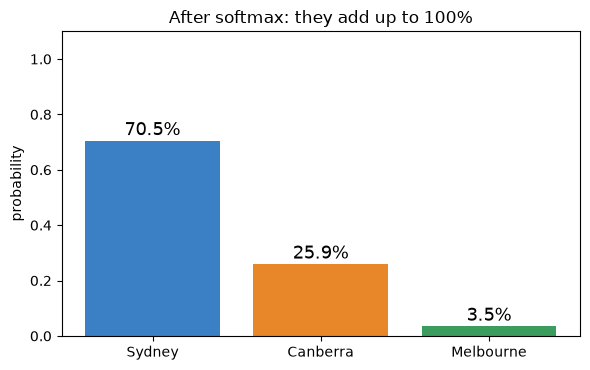

In [4]:
e = torch.exp(scores)
probs = e / e.sum()
print("exp: ", e)
print("probs: ", probs)
print("They add up to: ", probs.sum().item())
show_probs(probs, options)

## Softmax - converts logits into probabilities


In [5]:
print(torch.softmax(scores, dim = 0))
print(torch.softmax(scores + 100, dim = 0))
print(torch.softmax(scores * 3, dim = 0))
print(torch.softmax(scores / 3, dim = 0))

tensor([0.705, 0.259, 0.035])
tensor([0.705, 0.259, 0.035])
tensor([0.952, 0.047, 0.000])
tensor([0.480, 0.344, 0.176])


## Penalty curve

Sure of the right answer:  0.99 -> penalty 0.01
Sure of the right answer:  0.9 -> penalty 0.105
Sure of the right answer:  0.5 -> penalty 0.693
Sure of the right answer:  0.26 -> penalty 1.347
Sure of the right answer:  0.1 -> penalty 2.303
Sure of the right answer:  0.01 -> penalty 4.605


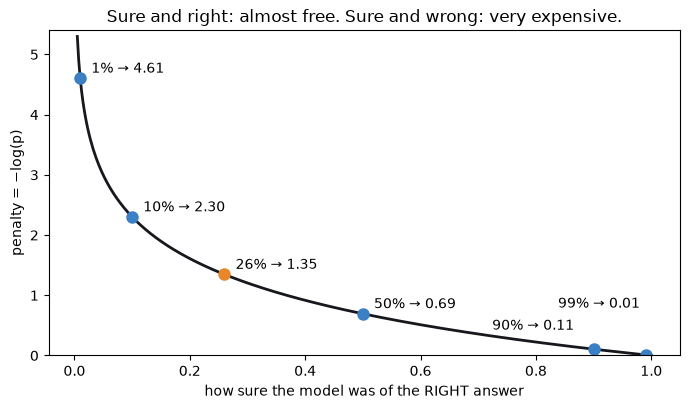

In [6]:
for p in [0.99, 0.9, 0.5, 0.26, 0.1, 0.01]:
    penalty = -math.log(p)
    print("Sure of the right answer: ", p, "-> penalty", round(penalty, 3))
show_penalty()

In [10]:
loss_fn = nn.CrossEntropyLoss()
answer = torch.tensor([1])
contestants = {
    "sure and right": [[0.0, 4.0, 0.0]],
    "no idea":        [[0.0, 0.0, 0.0]],
    "sure and wrong": [[79, 78.0, 76.0]],
}

for name, s in contestants.items():
    loss = loss_fn(torch.tensor(s), answer)
    print(name, "-> loss", round(loss.item(), 3))

sure and right -> loss 0.036
no idea -> loss 1.099
sure and wrong -> loss 1.349


In [12]:
torch.softmax(torch.tensor([[79, 78.0, 76.0]]), dim = 0)

tensor([[1., 1., 1.]])

In [13]:
my_scores = scores.reshape(1,3)
loss = loss_fn(my_scores, answer)
print("Pytorch loss: ", round(loss.item(), 3))



Pytorch loss:  1.349


In [15]:
my_scores.shape

torch.Size([1, 3])

In [16]:
p = torch.softmax(my_scores, dim = 1)[0,1]  ## how sure are you of canberra
print('Sure of canberra: ', round(p.item(), 3))
print("-log by hand: ", round(-math.log(p.item(), 3)))


Sure of canberra:  0.259
-log by hand:  1


In [17]:
df = pd.read_csv("spirals.csv")
X = torch.tensor(df[['x1', 'x2']].values).float()
y = torch.tensor(df['label'].values)


In [18]:
X.shape

torch.Size([3600, 2])

torch.Size([3000, 2]) torch.Size([3000]) torch.int64


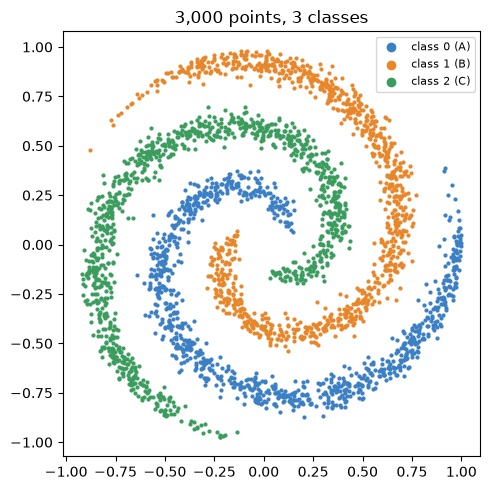

In [20]:
X_train, y_train = X[:3000], y[:3000]
X_test, y_test = X[3000:], y[3000:]

train_data = TensorDataset(X_train, y_train)
print(X_train.shape, y_train.shape, y_train.dtype)
show_spirals(X_train, y_train)

In [21]:
def new_model_c(n_classes = 3):
    return nn.Sequential(
        nn.Linear(2, 16), nn.ReLU(),
        nn.Linear(16,16), nn.ReLU(),
        nn.Linear(16, n_classes),
    )

torch.manual_seed(42)
model = new_model_c()
print(model(X_train[:2]))

tensor([[-0.420, -0.067,  0.165],
        [-0.370, -0.011,  0.358]], grad_fn=<AddmmBackward0>)


## Lets calculate the loss for the above model

In [22]:
with torch.no_grad():
    start_loss = loss_fn(model(X_train), y_train)
print("Loss after training: ", round(start_loss.item(), 3))
print("No idea loss, -log(1,3): ", round(-math.log(1/3), 3))

Loss after training:  1.134
No idea loss, -log(1,3):  1.099


In [27]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    losses = []
    for xb, yb in loader:
        prediction = model(xb)
        loss = loss_fn(prediction, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

In [28]:
def accuracy(model, X, y):
    with torch.no_grad():
        picked = model(X).argmax(dim = 1)
    return round((picked == y).float().mean().item(), 3)

print("accuracy before training: ", accuracy(model, X_test, y_test))

accuracy before training:  0.308


In [29]:
torch.manual_seed(42)
model = new_model_c()
optimizer = torch.optim.SGD(model.parameters(), lr = 0.1)
loader = DataLoader(train_data, batch_size = 32, shuffle=True)

for epoch in range(1,41):
    losses = train_one_epoch(model, loader, loss_fn, optimizer)
    if epoch in [1,10, 20, 30, 40]:
        loss = round(sum(losses) / len(losses), 3)
        acc = accuracy(model, X_test, y_test)
        print("Epoch: ", epoch, "| loss: ", loss, "| test accuracy:", acc)

Epoch:  1 | loss:  1.061 | test accuracy: 0.547
Epoch:  10 | loss:  0.568 | test accuracy: 0.762
Epoch:  20 | loss:  0.171 | test accuracy: 0.96
Epoch:  30 | loss:  0.111 | test accuracy: 0.965
Epoch:  40 | loss:  0.055 | test accuracy: 0.987


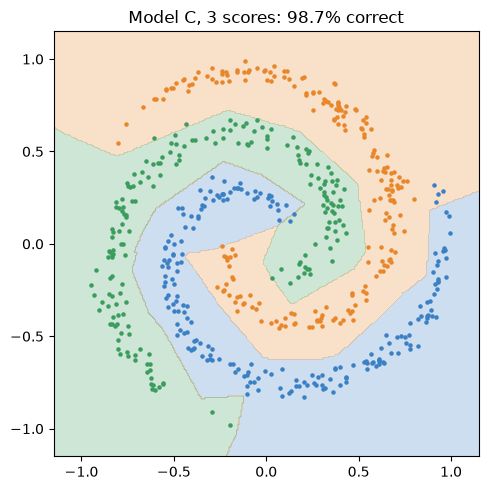

In [30]:
show_regions(model, X_test, y_test, "Model C, 3 scores")

In [31]:
points = torch.tensor([[0.73, -0.53], [0.0, 0.0], [-0.5, 0.5]])
with torch.no_grad():
    probs = torch.softmax(model(points), dim = 1)  # dim = 1 each row
print((probs * 100).round())

tensor([[100.,   0.,   0.],
        [  1.,  66.,  33.],
        [  1.,   2.,  97.]])


## Mistake 1:  Mistakes with softmax

In [32]:
torch.manual_seed(42)
model_bug = nn.Sequential(new_model_c(), nn.Softmax(dim = 1))  # the bug
optimizer = torch.optim.SGD(model_bug.parameters(), lr =0.1)
loader = DataLoader(train_data, batch_size=32, shuffle = True)

for epoch in range(1, 41):
    losses = train_one_epoch(model_bug, loader, loss_fn, optimizer)
    if epoch in [1, 10, 20, 30, 40]:
        loss = round(sum(losses) / len(losses), 3)
        acc =  accuracy(model_bug, X_test, y_test)
        print("Epoch: ", epoch, "| loss: ", loss, "| test accuracy:", acc)


Epoch:  1 | loss:  1.098 | test accuracy: 0.308
Epoch:  10 | loss:  0.937 | test accuracy: 0.593
Epoch:  20 | loss:  0.89 | test accuracy: 0.65
Epoch:  30 | loss:  0.801 | test accuracy: 0.775
Epoch:  40 | loss:  0.754 | test accuracy: 0.803


# Mistake 2: Labels in the wrong shape

In [34]:
y_train.shape

torch.Size([3000])

In [36]:
mistakes = {
    "labels as decimal values": y_train.float(),
    "labels as a column": y_train.reshape(-1,1), 
}

with torch.no_grad():
    scores_all = model(X_train)

for name, labels in mistakes.items():
    try:
        loss_fn(scores_all, labels)
    except RuntimeError as e:
        print(name, "->", e)

labels as decimal values -> expected target dtype to be Long or Byte, but got Float
labels as a column -> 0D or 1D target tensor expected, multi-target not supported


## Mistake 3: No hidden layers

Test accuracy:  0.53


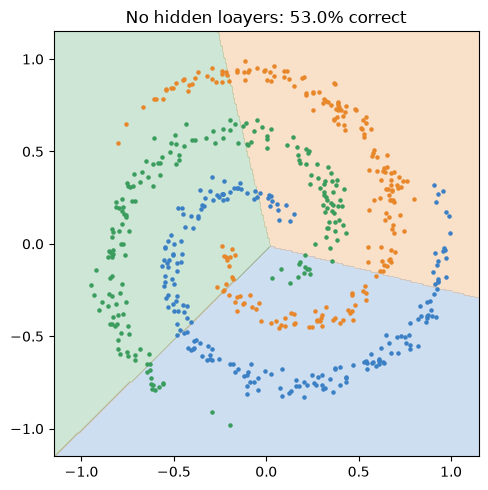

In [37]:
torch.manual_seed(42)
model_line = nn.Linear(2, 3)
optimizer = torch.optim.SGD(model_line.parameters(), lr = 0.1)
loader = DataLoader(train_data, batch_size = 32, shuffle=True)

for epoch in range(1, 41):
    train_one_epoch(model_line, loader, loss_fn, optimizer)
print("Test accuracy: ", accuracy(model_line, X_test, y_test))
show_regions(model_line, X_test, y_test, "No hidden loayers")

In [41]:
df5 = pd.read_csv("spirals5.csv")
X5 = torch.tensor(df5[["x1", "x2"]].values).float()
y5 = torch.tensor(df5['label'].values)


In [42]:
X5.shape

torch.Size([6000, 2])

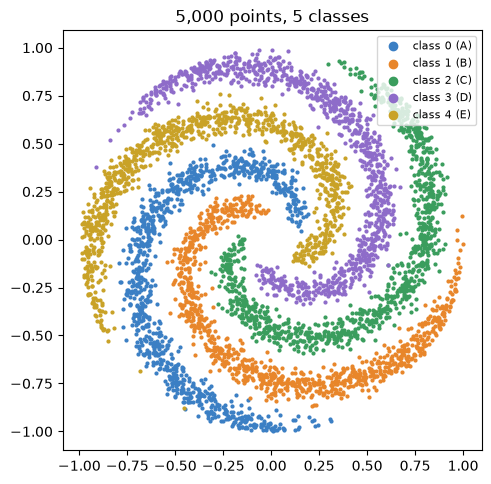

In [43]:
X5_train, y5_train = X5[:5000], y5[:5000]
X5_test, y5_test = X5[5000:], y5[5000:]
train5 = TensorDataset(X5_train, y5_train)
show_spirals(X5_train, y5_train)

In [45]:
torch.manual_seed(42)
model5 = new_model_c(n_classes = 5)
# model eval
with torch.no_grad():
    start_loss = loss_fn(model5(X5_train), y5_train)
print("Loss before training: ", round(start_loss.item(), 3))
print("No idea loss, -log(1/5)", round(-math.log(1/5), 3))

Loss before training:  1.597
No idea loss, -log(1/5) 1.609


Epoch:  1 | test accuracy:  0.444
Epoch:  10 | test accuracy:  0.716
Epoch:  20 | test accuracy:  0.832
Epoch:  30 | test accuracy:  0.965
Epoch:  40 | test accuracy:  0.975


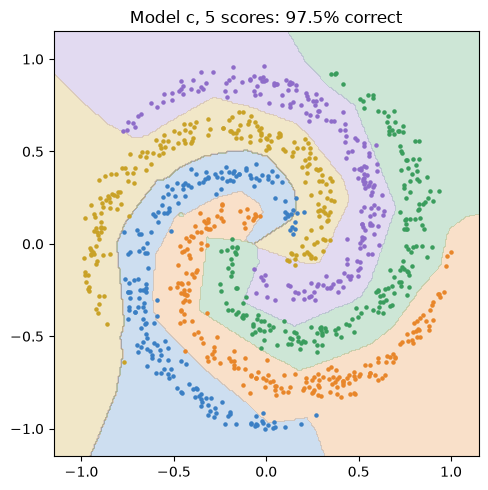

In [46]:
optimizer = torch.optim.SGD(model5.parameters(), lr = 0.1)
loader = DataLoader(train5, batch_size = 32, shuffle=True)

for epoch in range(1, 41):
    train_one_epoch(model5, loader, loss_fn, optimizer)
    if epoch in [1, 10, 20, 30, 40]:
        acc = accuracy(model5, X5_test, y5_test)
        print("Epoch: ", epoch, "| test accuracy: ", acc)
show_regions(model5, X5_test, y5_test, "Model c, 5 scores")

## Which loss for which question

## Single value = nn.MSELoss()
## Yes or No or (binary question) = nn.BCEWithLogitsLoss()

## Labels > 2  loss = nn.CrossEntropyLoss()

## both BCEWithLogitsLoss() and CrossEntropyLoss() has softmax in it 